In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("eda_outputs", exist_ok=True)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

df = pd.read_csv("../data/raw/synthetic_projects.csv")

In [15]:
%pip install  matplotlib

Note: you may need to restart the kernel to use updated packages.


In [16]:
print("="*60)
print("1. BASIC STRUCTURE")
print("="*60)
print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
print("\nFirst 5 rows:\n", df.head())

1. BASIC STRUCTURE
Shape: (3000, 19)

Dtypes:
 project_id                     object
project_name                   object
project_type                   object
state                          object
district                       object
land_area_hectares            float64
affected_families               int64
compensation_disbursed_pct    float64
active_legal_disputes           int64
possession_pct                float64
rnr_progress_pct              float64
stakeholder_responsiveness    float64
dept_historical_delay_rate    float64
days_since_notification         int64
planned_completion_days         int64
true_risk_debug               float64
is_delayed                      int64
delay_days                      int64
actual_completion_days          int64
dtype: object

First 5 rows:
     project_id                project_name      project_type      state         district  land_area_hectares  affected_families  compensation_disbursed_pct  \
0  LA-OD-00000  Irrigation Canal Project 0

Data Quality Checks

In [17]:
print("\n" + "="*60)
print("2. DATA QUALITY")
print("="*60)
print("Missing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate project_id:", df["project_id"].duplicated().sum())


2. DATA QUALITY
Missing values per column:
 project_id                    0
project_name                  0
project_type                  0
state                         0
district                      0
land_area_hectares            0
affected_families             0
compensation_disbursed_pct    0
active_legal_disputes         0
possession_pct                0
rnr_progress_pct              0
stakeholder_responsiveness    0
dept_historical_delay_rate    0
days_since_notification       0
planned_completion_days       0
true_risk_debug               0
is_delayed                    0
delay_days                    0
actual_completion_days        0
dtype: int64

Duplicate rows: 0
Duplicate project_id: 0


Statistical Summary

In [18]:
print("\n" + "="*60)
print("3. NUMERIC SUMMARY")
print("="*60)
print(df.describe().T)

print("\nCategorical value counts:")
for col in ["project_type", "state"]:
    print(f"\n--{col}--\n", df[col].value_counts())


3. NUMERIC SUMMARY
                             count        mean         std     min      25%     50%      75%      max
land_area_hectares          3000.0   75.515800   59.171679    5.00   37.175   58.25   94.125   400.00
affected_families           3000.0  177.869000  116.839809   20.00  101.000  148.00  220.250  1098.00
compensation_disbursed_pct  3000.0   41.963833   19.923722    1.30   26.500   40.30   56.700    96.80
active_legal_disputes       3000.0    1.299000    1.157603    0.00    0.000    1.00    2.000     6.00
possession_pct              3000.0   50.043567   23.342248    5.00   30.375   50.00   69.500    95.00
rnr_progress_pct            3000.0   27.091167   21.244572    3.00    5.300   24.30   43.600    80.60
stakeholder_responsiveness  3000.0    0.390470    0.231332    0.05    0.180    0.39    0.590     0.87
dept_historical_delay_rate  3000.0    0.585630    0.137241    0.13    0.490    0.60    0.690     0.95
days_since_notification     3000.0  213.590333  106.612153   3

Target Balance

In [19]:
print("\n" + "="*60)
print("4. TARGET BALANCE")
print("="*60)
print(df["is_delayed"].value_counts(normalize=True))


4. TARGET BALANCE
is_delayed
0    0.621
1    0.379
Name: proportion, dtype: float64


Outlier Check

In [20]:
print(df.columns.tolist())

['project_id', 'project_name', 'project_type', 'state', 'district', 'land_area_hectares', 'affected_families', 'compensation_disbursed_pct', 'active_legal_disputes', 'possession_pct', 'rnr_progress_pct', 'stakeholder_responsiveness', 'dept_historical_delay_rate', 'days_since_notification', 'planned_completion_days', 'true_risk_debug', 'is_delayed', 'delay_days', 'actual_completion_days']


In [21]:
# Rule: only check columns that are (a) numeric, (b) continuous/unbounded
# (not 0-100 percentages or 0-1 scores, since extreme values there are
# still "valid" within their fixed range), and (c) have wide enough range
# for IQR to be meaningful (not small-range counts like legal disputes).

print("\n" + "="*60)
print("5. OUTLIER CHECK (IQR method, unbounded numeric columns only)")
print("="*60)
unbounded_cols = ["land_area_hectares", "affected_families",
                   "days_since_notification", "planned_completion_days"]
for col in unbounded_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: bounds=[{lower:.1f}, {upper:.1f}]  outliers={n_out} ({n_out/len(df):.1%})")


5. OUTLIER CHECK (IQR method, unbounded numeric columns only)
land_area_hectares: bounds=[-48.2, 179.6]  outliers=172 (5.7%)
affected_families: bounds=[-77.9, 399.1]  outliers=152 (5.1%)
days_since_notification: bounds=[-153.1, 579.9]  outliers=0 (0.0%)
planned_completion_days: bounds=[-2.1, 722.9]  outliers=0 (0.0%)


Distribution Plots

In [22]:
import os
import shutil
import matplotlib

cache_dir = matplotlib.get_cachedir()

for file in os.listdir(cache_dir):
    if file.startswith("fontlist"):
        path = os.path.join(cache_dir, file)
        if os.path.isfile(path):
            os.remove(path)

print("Matplotlib font cache cleared.")
print("Cache location:", cache_dir)

Matplotlib font cache cleared.
Cache location: C:\Users\sneha\.matplotlib


In [23]:
import os
import matplotlib

font_path = os.path.join(
    matplotlib.get_data_path(),
    "fonts", "ttf", "LastResortHE-Regular.ttf"
)

print("Matplotlib:", matplotlib.__file__)
print("Font exists:", os.path.exists(font_path))
print("Font path:", font_path)

Matplotlib: c:\Users\sneha\anaconda3\Lib\site-packages\matplotlib\__init__.py
Font exists: False
Font path: c:\Users\sneha\anaconda3\Lib\site-packages\matplotlib\mpl-data\fonts\ttf\LastResortHE-Regular.ttf


In [1]:
import os
import glob
import matplotlib

cache_dir = matplotlib.get_cachedir()
print("Cache folder:", cache_dir)

for file in glob.glob(os.path.join(cache_dir, "fontlist*")):
    try:
        os.remove(file)
        print("Deleted:", file)
    except OSError as e:
        print("Could not delete:", e)

print("Done")

Cache folder: C:\Users\sneha\.matplotlib
Deleted: C:\Users\sneha\.matplotlib\fontlist-v3.11.0.json
Done


In [9]:
import pandas as pd


df = pd.read_csv("../data/raw/synthetic_projects.csv")

df.head()

,project_id,project_name,project_type,state,district,land_area_hectares,affected_families,compensation_disbursed_pct,active_legal_disputes,possession_pct,rnr_progress_pct,stakeholder_responsiveness,dept_historical_delay_rate,days_since_notification,planned_completion_days,true_risk_debug,is_delayed,delay_days,actual_completion_days
0,LA-OD-00000,Irrigation Canal Project 0,Irrigation Canal,Odisha,Cuttack,55.4,295,52.7,1,49.1,31.1,0.51,0.67,338,432,35.0,0,0,430
1,LA-GU-00001,Irrigation Canal Project 1,Irrigation Canal,Gujarat,Vadodara,73.5,156,28.3,0,68.2,33.9,0.56,0.67,240,230,39.6,1,1245,1475
2,LA-GU-00002,Irrigation Canal Project 2,Irrigation Canal,Gujarat,Vadodara,109.4,113,24.4,1,43.7,4.9,0.12,0.63,134,285,52.2,1,651,936
3,LA-KA-00003,Irrigation Canal Project 3,Irrigation Canal,Karnataka,Belagavi,60.5,113,60.3,1,23.2,3.0,0.41,0.42,141,406,32.3,0,0,400
4,LA-KA-00004,Rail Corridor Project 4,Rail Corridor,Karnataka,Bengaluru Rural,47.3,84,31.3,4,35.5,17.2,0.20,0.68,95,488,66.2,1,1203,1691


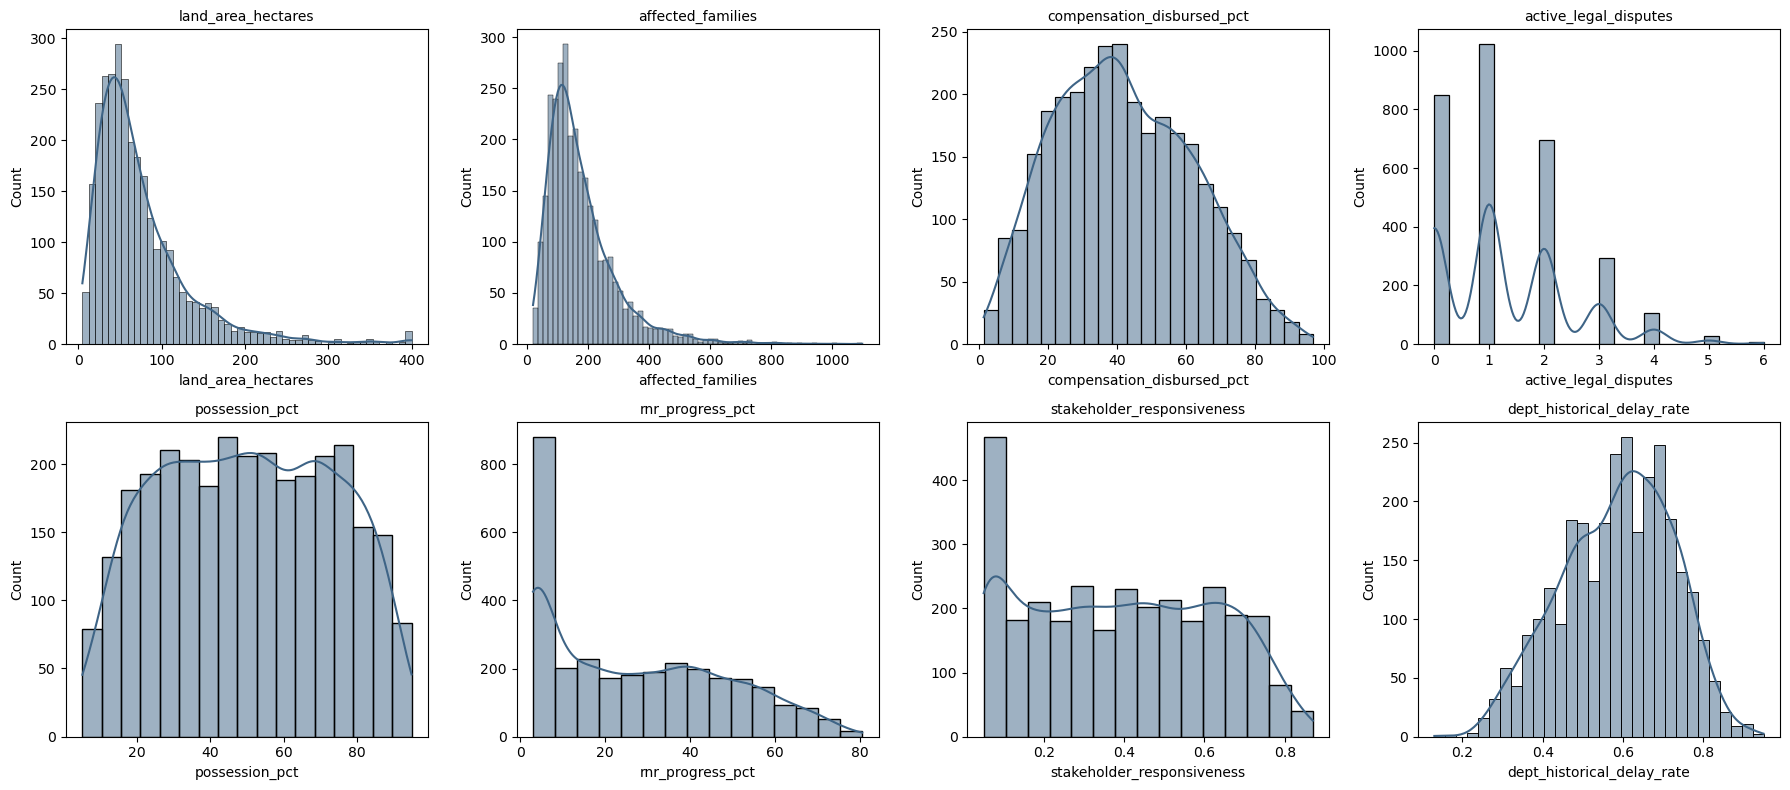

In [10]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("eda_outputs", exist_ok=True)

numeric_cols = [
    "land_area_hectares",
    "affected_families",
    "compensation_disbursed_pct",
    "active_legal_disputes",
    "possession_pct",
    "rnr_progress_pct",
    "stakeholder_responsiveness",
    "dept_historical_delay_rate"
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, col in zip(axes.flatten(), numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="#3E6486")
    ax.set_title(col, fontsize=10)

plt.tight_layout()
fig.savefig("eda_outputs/distributions.png", dpi=110)
plt.show()
plt.close(fig)

In [1]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot([1, 2, 3], [1, 4, 9])
plt.savefig("font_test.png")
plt.close()

print("Plot saved successfully!")

Plot saved successfully!


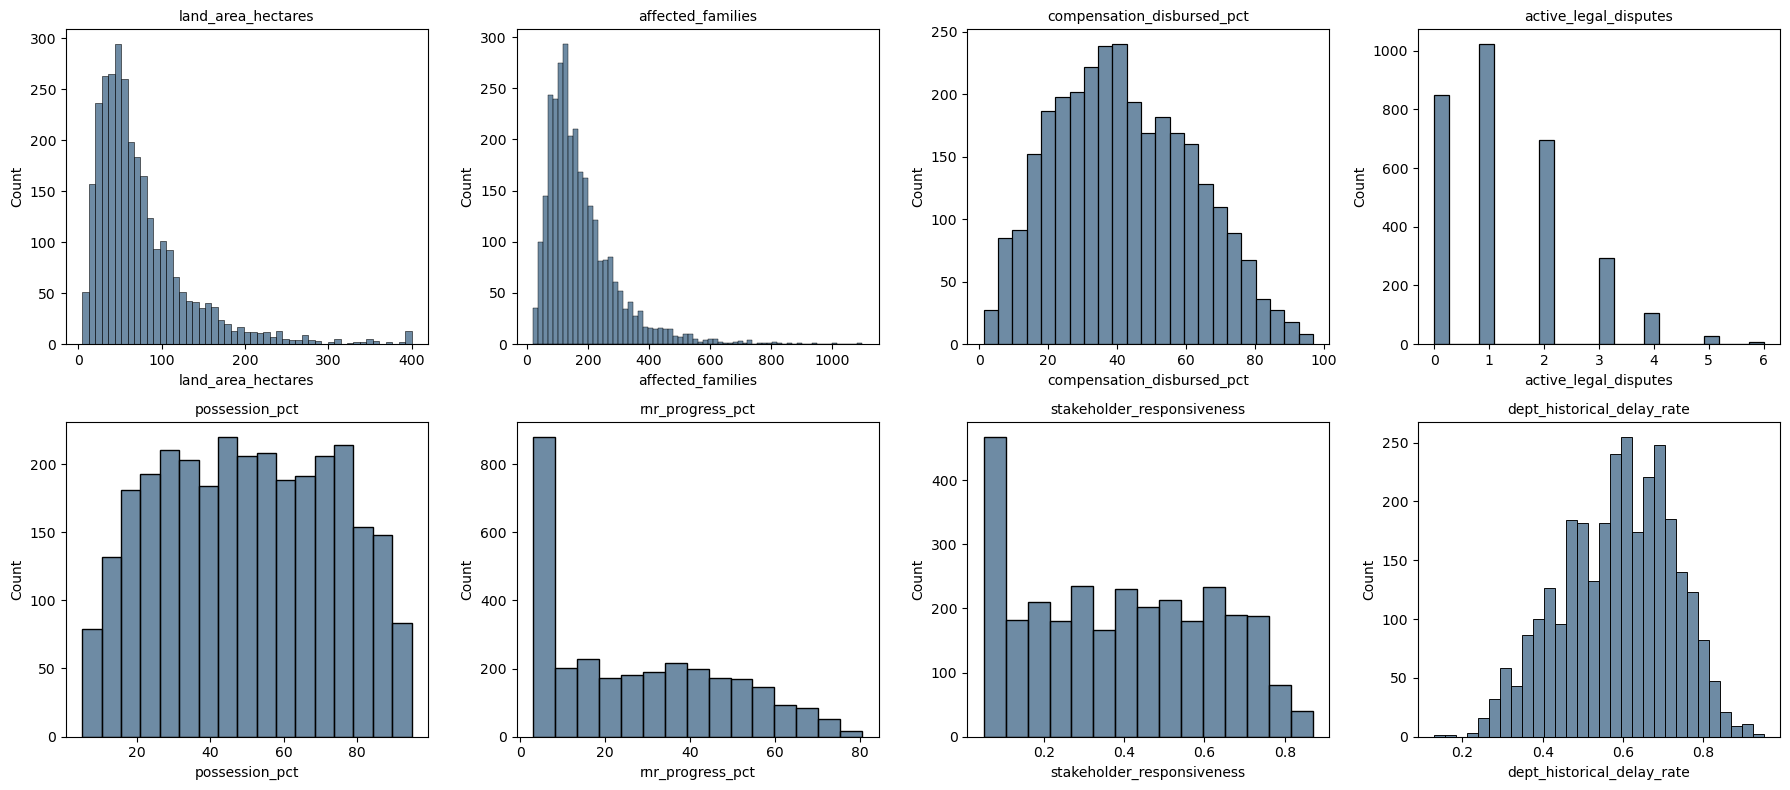

In [11]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("eda_outputs", exist_ok=True)

# Use a standard font
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["text.usetex"] = False

numeric_cols = [
    "land_area_hectares",
    "affected_families",
    "compensation_disbursed_pct",
    "active_legal_disputes",
    "possession_pct",
    "rnr_progress_pct",
    "stakeholder_responsiveness",
    "dept_historical_delay_rate"
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, col in zip(axes.flat, numeric_cols):
    sns.histplot(
        data=df,
        x=col,
        kde=False,
        ax=ax,
        color="#3E6486"
    )
    ax.set_title(col, fontsize=10)

fig.tight_layout()
fig.savefig("eda_outputs/distributions.png", dpi=110)
plt.show()
plt.close(fig)

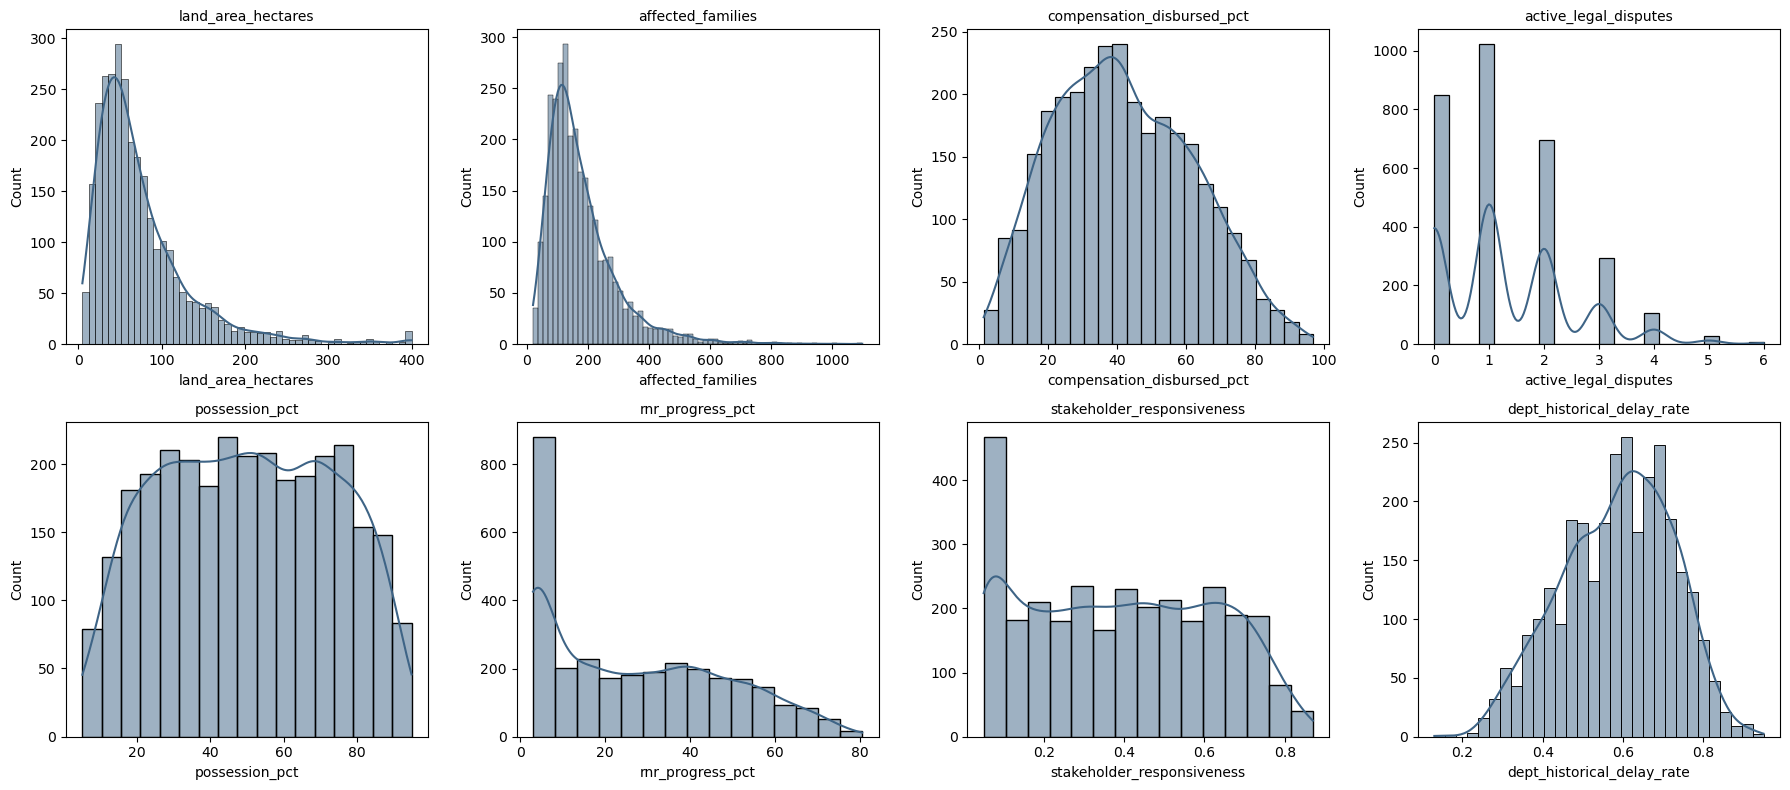

In [12]:
numeric_cols = ["land_area_hectares", "affected_families", "compensation_disbursed_pct",
                 "active_legal_disputes", "possession_pct", "rnr_progress_pct",
                 "stakeholder_responsiveness", "dept_historical_delay_rate"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="#3E6486")
    ax.set_title(col, fontsize=10)
plt.tight_layout()
plt.savefig("eda_outputs/distributions.png", dpi=110)
plt.show()

In [4]:
!python -m pip show matplotlib

^C


Name: matplotlib
Version: 3.11.2
Summary: Python plotting package
Home-page: https://matplotlib.org
Author: John D. Hunter, Michael Droettboom
Author-email: Unknown <matplotlib-users@python.org>
License: License agreement for matplotlib versions 1.3.0 and later

 1. This LICENSE AGREEMENT is between the Matplotlib Development Team
 ("MDT"), and the Individual or Organization ("Licensee") accessing and
 otherwise using matplotlib software in source or binary form and its
 associated documentation.

 2. Subject to the terms and conditions of this License Agreement, MDT
 hereby grants Licensee a nonexclusive, royalty-free, world-wide license
 to reproduce, analyze, test, perform and/or display publicly, prepare
 derivative works, distribute, and otherwise use matplotlib
 alone or in any derivative version, provided, however, that MDT's
 License Agreement and MDT's notice of copyright, i.e., "Copyright (c)
 2012- Matplotlib Development Team; All Rights Reserved" are retained in
 matplotlib

Correlation Heatmap

In [7]:
import matplotlib.pyplot as plt
print("Matplotlib imported")

In c:\Users\sneha\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\bmh.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
In c:\Users\sneha\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
In c:\Users\sneha\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\_classic_test_patch.mplstyle: The text.kerning_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.


Matplotlib imported


In [6]:
print("Python is working")

Python is working


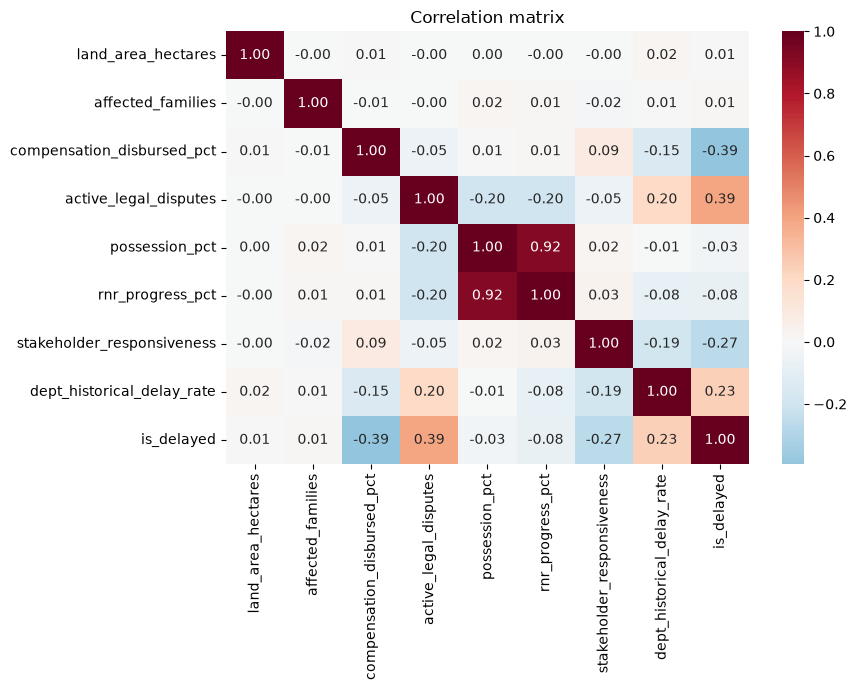

In [ ]:
corr_cols = numeric_cols + ["is_delayed"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig("eda_outputs/correlation.png", dpi=110)
plt.show()

Target-wise Boxplot

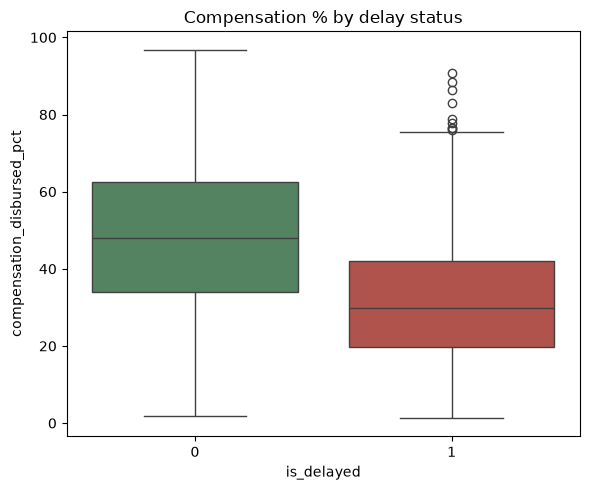

In [ ]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=df, x="is_delayed", y="compensation_disbursed_pct",
            hue="is_delayed", palette={0: "#4C8B5D", 1: "#C1443C"}, legend=False)
plt.title("Compensation % by delay status")
plt.tight_layout()
plt.savefig("eda_outputs/compensation_by_delay.png", dpi=110)
plt.show()

In [20]:
%pip install ydata-profiling

  Using cached ydata_profiling-4.18.4-py2.py3-none-any.whl.metadata (23 kB)
  Using cached matplotlib-3.10.0-cp313-cp313-win_amd64.whl.metadata (11 kB)
  Using cached phik-0.12.5-cp313-cp313-win_amd64.whl.metadata (5.6 kB)
  Using cached ImageHash-4.3.2-py2.py3-none-any.whl.metadata (8.4 kB)
  Using cached wordcloud-1.9.6-cp313-cp313-win_amd64.whl.metadata (3.5 kB)
Using cached ydata_profiling-4.18.4-py2.py3-none-any.whl (400 kB)
Using cached ImageHash-4.3.2-py2.py3-none-any.whl (296 kB)
Using cached matplotlib-3.10.0-cp313-cp313-win_amd64.whl (8.0 MB)
Using cached phik-0.12.5-cp313-cp313-win_amd64.whl (678 kB)
Using cached wordcloud-1.9.6-cp313-cp313-win_amd64.whl (306 kB)

  Attempting uninstall: matplotlib

    Found existing installation: matplotlib 3.11.2

   ---------------------------------------- 0/5 [matplotlib]

Note: you may need to restart the kernel to use updated packages.


error: uninstall-no-record-file

× Cannot uninstall matplotlib 3.11.2
╰─> The package's contents are unknown: no RECORD file was found for matplotlib.

hint: You might be able to recover from this via: pip install --ignore-installed --no-deps matplotlib==3.11.2


In [25]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the correct dataset
df = pd.read_csv("../data/raw/synthetic_projects.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

# 2. Create output folders
os.makedirs("eda_outputs/plots", exist_ok=True)

# 3. Dataset overview
overview = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Duplicate Rows",
        "Missing Values"
    ],
    "Value": [
        df.shape[0],
        df.shape[1],
        df.duplicated().sum(),
        df.isnull().sum().sum()
    ]
})

# 4. Missing values
missing = pd.DataFrame({
    "Column": df.columns,
    "Missing Values": df.isnull().sum().values,
    "Missing Percentage": (
        df.isnull().mean().values * 100
    ).round(2)
})

# 5. Descriptive statistics
stats = df.describe(include="all").transpose()

# 6. Numeric columns
numeric_cols = df.select_dtypes(include="number").columns.tolist()

# 7. Distribution plots
if numeric_cols:
    ncols = 2
    nrows = (len(numeric_cols) + ncols - 1) // ncols

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(14, 4 * nrows)
    )
    axes = __import__("numpy").array(axes).reshape(-1)

    for ax, col in zip(axes, numeric_cols):
        sns.histplot(
            df[col].dropna(),
            kde=False,
            ax=ax,
            color="#3E6486"
        )
        ax.set_title(col, fontsize=10)

    for ax in axes[len(numeric_cols):]:
        ax.set_visible(False)

    fig.tight_layout()
    fig.savefig("eda_outputs/plots/distributions.png", dpi=110)
    plt.close(fig)

# 8. Correlation heatmap
if len(numeric_cols) >= 2:
    corr = df[numeric_cols].corr()

    fig, ax = plt.subplots(figsize=(12, 8))
    sns.heatmap(corr, cmap="coolwarm", annot=True, fmt=".2f", ax=ax)
    ax.set_title("Correlation Heatmap")
    fig.tight_layout()
    fig.savefig("eda_outputs/plots/correlation.png", dpi=110)
    plt.close(fig)

# 9. Generate HTML report
overview_html = overview.to_html(index=False)
missing_html = missing.to_html(index=False)
stats_html = stats.to_html()

html = f"""
<html>
<head>
<meta charset="UTF-8">
<title>Land Acquisition Dataset - EDA Report</title>
<style>
body {{ font-family: Arial, sans-serif; margin: 30px; }}
h1, h2 {{ color: #254b70; }}
table {{ border-collapse: collapse; width: 100%; margin-bottom: 25px; }}
th, td {{ border: 1px solid #ddd; padding: 8px; }}
th {{ background: #e8eef4; }}
img {{ max-width: 100%; }}
</style>
</head>
<body>
<h1>Land Acquisition Dataset - EDA Report</h1>

<h2>1. Dataset Overview</h2>
{overview_html}

<h2>2. Missing Values</h2>
{missing_html}

<h2>3. Descriptive Statistics</h2>
{stats_html}

<h2>4. Numeric Distributions</h2>
<img src="plots/distributions.png">

<h2>5. Correlation Heatmap</h2>
<img src="plots/correlation.png">

</body>
</html>
"""

with open("eda_outputs/profiling_report.html", "w", encoding="utf-8") as f:
    f.write(html)

print("EDA report created successfully!")
print("Report location: eda_outputs/profiling_report.html")


Dataset loaded successfully!
Shape: (3000, 19)
EDA report created successfully!
Report location: eda_outputs/profiling_report.html
